In [35]:
# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [36]:
# 2. Load the data
df = pd.read_csv("Mumbai House Prices.csv")
df.head()

,bhk,type,locality,area,price,price_unit,region,status,age
0,3,Apartment,Lak And Hanware The Residency Tower,685,2.50,Cr,Andheri West,Ready to move,New
1,2,Apartment,Radheya Sai Enclave Building No 2,640,52.51,L,Naigaon East,Under Construction,New
2,2,Apartment,Romell Serene,610,1.73,Cr,Borivali West,Under Construction,New
3,2,Apartment,Soundlines Codename Urban Rainforest,876,59.98,L,Panvel,Under Construction,New
4,2,Apartment,Origin Oriana,659,94.11,L,Mira Road East,Under Construction,New


In [37]:
# 3. Basic information
print("Shape:", df.shape)
print()
df.info()

Shape: (76038, 9)

<class 'pandas.DataFrame'>
RangeIndex: 76038 entries, 0 to 76037
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   bhk         76038 non-null  int64  
 1   type        76038 non-null  str    
 2   locality    76038 non-null  str    
 3   area        76038 non-null  int64  
 4   price       76038 non-null  float64
 5   price_unit  76038 non-null  str    
 6   region      76038 non-null  str    
 7   status      76038 non-null  str    
 8   age         76038 non-null  str    
dtypes: float64(1), int64(2), str(6)
memory usage: 9.7 MB


In [38]:
# 4. Summary statistics
df.describe()

,bhk,area,price
count,76038.000000,76038.000000,76038.00000
mean,2.015111,1024.536850,29.38227
std,0.922754,670.276165,32.90345
min,1.000000,127.000000,1.00000
25%,1.000000,640.000000,1.75000
50%,2.000000,872.000000,5.50000
75%,3.000000,1179.000000,59.00000
max,10.000000,16000.000000,99.99000


In [39]:
# 5. Missing values
print(df.isnull().sum())

bhk           0
type          0
locality      0
area          0
price         0
price_unit    0
region        0
status        0
age           0
dtype: int64


In [40]:
# 6. Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 20312


In [41]:
# 7. Look at the categorical columns
for col in ["type", "price_unit", "status", "age"]:
    print(df[col].value_counts())
    print()
print("Unique localities:", df["locality"].nunique())
print("Unique regions:", df["region"].nunique())

type
Apartment            74854
Studio Apartment       882
Villa                  226
Independent House       73
Penthouse                3
Name: count, dtype: int64

price_unit
Cr    40981
L     35057
Name: count, dtype: int64

status
Ready to move         44982
Under Construction    31056
Name: count, dtype: int64

age
New        38072
Resale     23357
Unknown    14609
Name: count, dtype: int64

Unique localities: 9782
Unique regions: 228


In [42]:
# ---------------- DATA CLEANING ----------------
# 8. Work on a copy so the original stays unchanged
data = df.copy()

In [43]:
# 9. Remove duplicate rows
before = len(data)
data = data.drop_duplicates()
print("Rows removed:", before - len(data))
print("Rows left:", len(data))

Rows removed: 20312
Rows left: 55726


In [44]:
# 10. Remove extra spaces in text columns
for col in ["type", "locality", "region", "status", "age", "price_unit"]:
    data[col] = data[col].str.strip()

In [45]:
# 11. Convert price to one unit (Lakhs)
# 1 Cr = 100 Lakhs
data["price_lakhs"] = np.where(data["price_unit"] == "Cr", data["price"] * 100, data["price"])
data[["price", "price_unit", "price_lakhs"]].head()

,price,price_unit,price_lakhs
0,2.50,Cr,250.00
1,52.51,L,52.51
2,1.73,Cr,173.00
3,59.98,L,59.98
4,94.11,L,94.11


In [46]:
# 12. Create price per sqft (in rupees)
# 1 Lakh = 100000 rupees
data["price_per_sqft"] = (data["price_lakhs"] * 100000) / data["area"]
data["price_per_sqft"].describe()

count     55726.000000
mean      14951.410105
std        9705.062860
min         646.766169
25%        8206.896552
50%       12420.919218
75%       19500.000000
max      182307.692308
Name: price_per_sqft, dtype: float64

In [47]:
# 13. Check the "Unknown" values in age
print(data["age"].value_counts())

age
New        27585
Resale     19606
Unknown     8535
Name: count, dtype: int64


In [48]:
# 14. Drop columns that are no longer needed
data = data.drop(columns=["price", "price_unit"])
data.head()

,bhk,type,locality,area,region,status,age,price_lakhs,price_per_sqft
0,3,Apartment,Lak And Hanware The Residency Tower,685,Andheri West,Ready to move,New,250.00,36496.350365
1,2,Apartment,Radheya Sai Enclave Building No 2,640,Naigaon East,Under Construction,New,52.51,8204.687500
2,2,Apartment,Romell Serene,610,Borivali West,Under Construction,New,173.00,28360.655738
3,2,Apartment,Soundlines Codename Urban Rainforest,876,Panvel,Under Construction,New,59.98,6847.031963
4,2,Apartment,Origin Oriana,659,Mira Road East,Under Construction,New,94.11,14280.728376


In [49]:
# 15. Check for impossible values
print("Area <= 0:", (data["area"] <= 0).sum())
print("BHK <= 0:", (data["bhk"] <= 0).sum())
print("Price <= 0:", (data["price_lakhs"] <= 0).sum())

Area <= 0: 0
BHK <= 0: 0
Price <= 0: 0


In [50]:
# 16. Find outliers in price per sqft using the IQR method
Q1 = data["price_per_sqft"].quantile(0.25)
Q3 = data["price_per_sqft"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print("Lower limit:", lower)
print("Upper limit:", upper)

outliers = data[(data["price_per_sqft"] < lower) | (data["price_per_sqft"] > upper)]
print("Number of outliers:", len(outliers))

Lower limit: -8732.758620689656
Upper limit: 36439.6551724138
Number of outliers: 1981


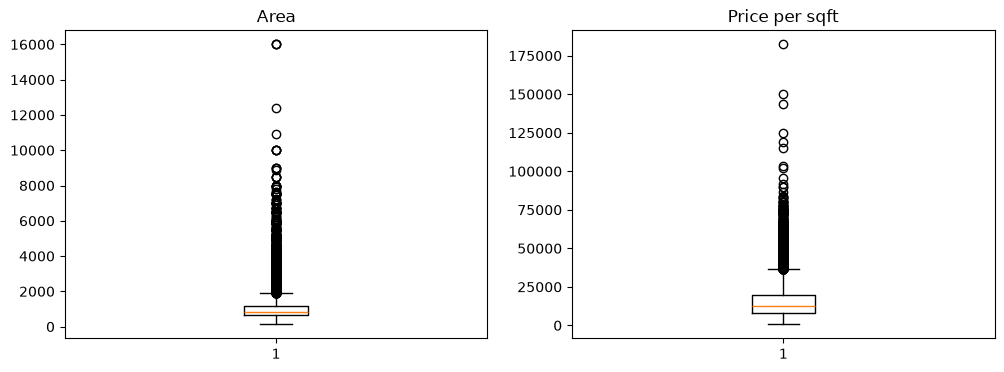

In [51]:
# 17. Boxplots before removing outliers
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.boxplot(data["area"])
plt.title("Area")

plt.subplot(1, 2, 2)
plt.boxplot(data["price_per_sqft"])
plt.title("Price per sqft")

plt.show()

In [52]:
# 18. Remove outliers
clean = data[(data["price_per_sqft"] >= lower) & (data["price_per_sqft"] <= upper)]

# also remove very large areas (above 99th percentile)
area_limit = clean["area"].quantile(0.99)
clean = clean[clean["area"] <= area_limit]

clean = clean.reset_index(drop=True)
print("Rows before:", len(data))
print("Rows after:", len(clean))

Rows before: 55726
Rows after: 53215


In [53]:
# ---------------- EDA ----------------
# 19. Summary of cleaned data
clean.describe()

,bhk,area,price_lakhs,price_per_sqft
count,53215.000000,53215.000000,53215.000000,53215.000000
mean,1.874904,925.294842,131.804575,13694.821916
std,0.811420,420.614890,108.737125,7251.589347
min,1.000000,136.000000,4.490000,646.766169
25%,1.000000,638.000000,60.000000,8084.672942
50%,2.000000,840.000000,97.000000,11873.350923
75%,2.000000,1100.000000,170.000000,18533.333333
max,7.000000,3000.000000,1070.000000,36438.356164


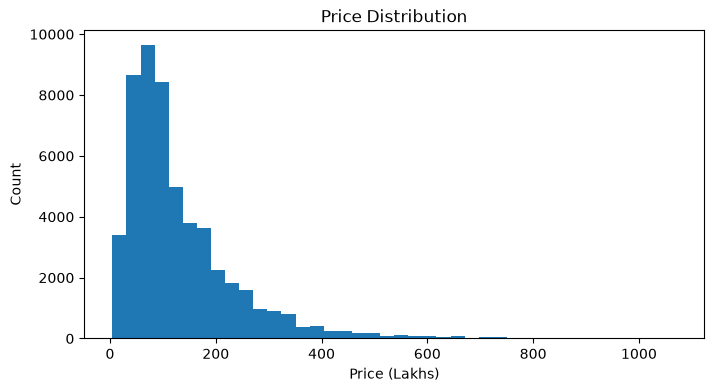

In [54]:
# 20. Distribution of price (lakhs)
plt.figure(figsize=(8, 4))
plt.hist(clean["price_lakhs"], bins=40)
plt.xlabel("Price (Lakhs)")
plt.ylabel("Count")
plt.title("Price Distribution")
plt.show()

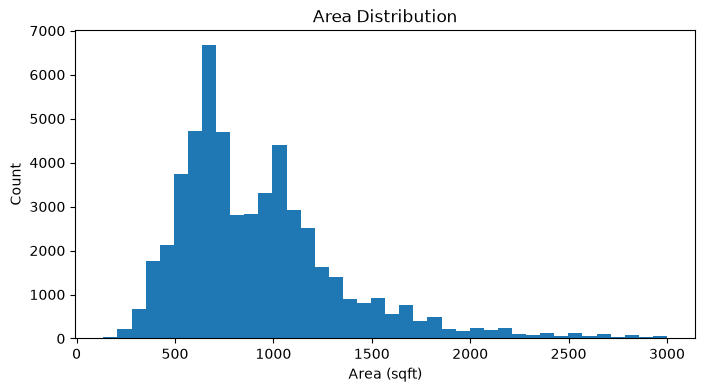

In [55]:
# 21. Distribution of area
plt.figure(figsize=(8, 4))
plt.hist(clean["area"], bins=40)
plt.xlabel("Area (sqft)")
plt.ylabel("Count")
plt.title("Area Distribution")
plt.show()

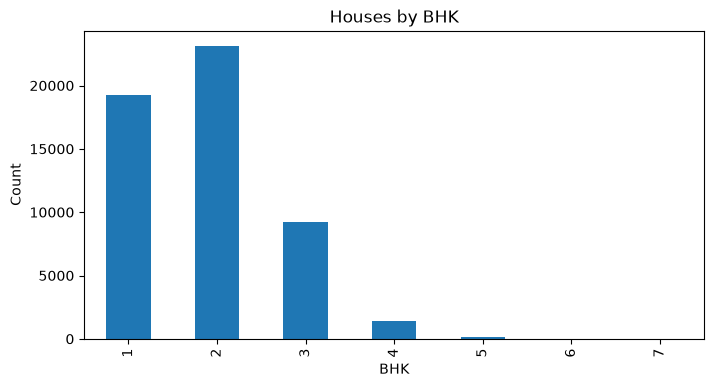

In [56]:
# 22. Number of houses by BHK
clean["bhk"].value_counts().sort_index().plot(kind="bar", figsize=(8, 4))
plt.xlabel("BHK")
plt.ylabel("Count")
plt.title("Houses by BHK")
plt.show()

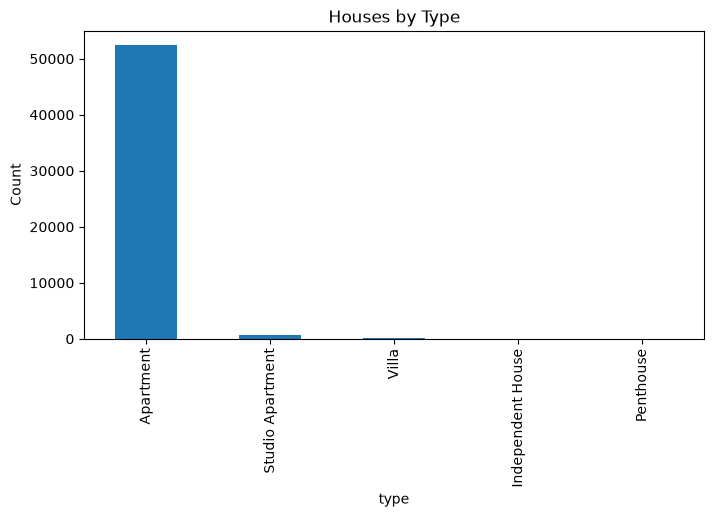

In [57]:
# 23. Number of houses by type
clean["type"].value_counts().plot(kind="bar", figsize=(8, 4))
plt.ylabel("Count")
plt.title("Houses by Type")
plt.show()

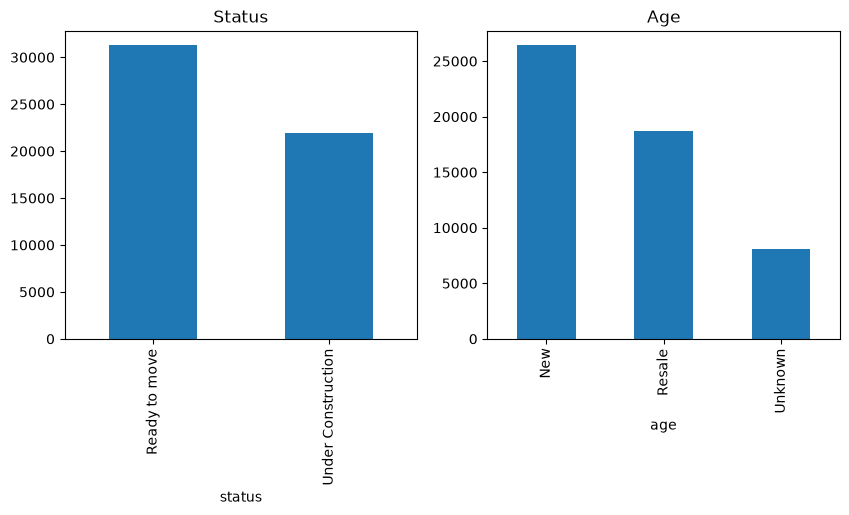

In [58]:
# 24. Status and age
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
clean["status"].value_counts().plot(kind="bar")
plt.title("Status")

plt.subplot(1, 2, 2)
clean["age"].value_counts().plot(kind="bar")
plt.title("Age")

plt.show()

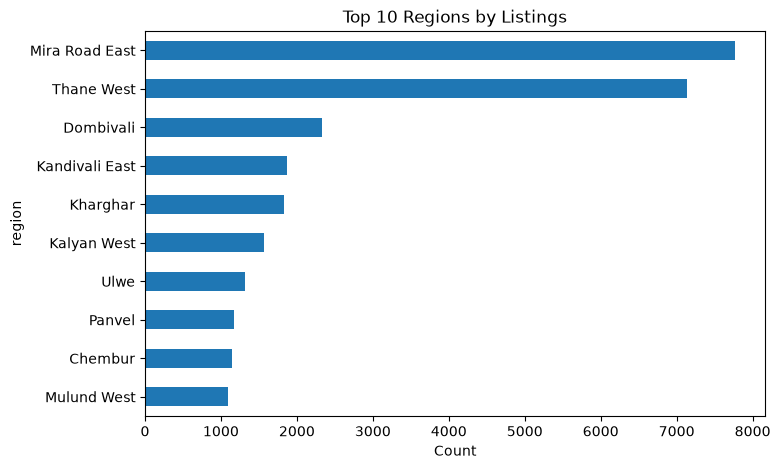

In [59]:
# 25. Top 10 regions by number of listings
clean["region"].value_counts().head(10).plot(kind="barh", figsize=(8, 5))
plt.xlabel("Count")
plt.title("Top 10 Regions by Listings")
plt.gca().invert_yaxis()
plt.show()

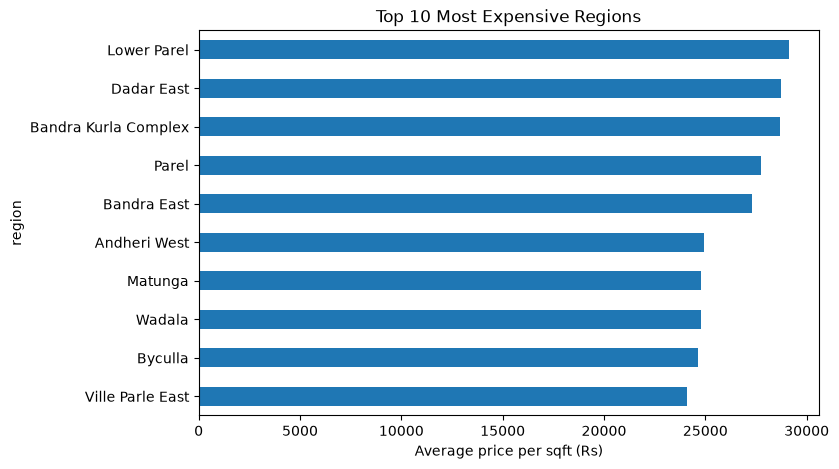

In [60]:
# 26. Average price per sqft by region (top 10 most expensive, regions with 50+ listings)
region_counts = clean["region"].value_counts()
big_regions = region_counts[region_counts >= 50].index
region_price = clean[clean["region"].isin(big_regions)].groupby("region")["price_per_sqft"].mean()
region_price.sort_values(ascending=False).head(10).plot(kind="barh", figsize=(8, 5))
plt.xlabel("Average price per sqft (Rs)")
plt.title("Top 10 Most Expensive Regions")
plt.gca().invert_yaxis()
plt.show()

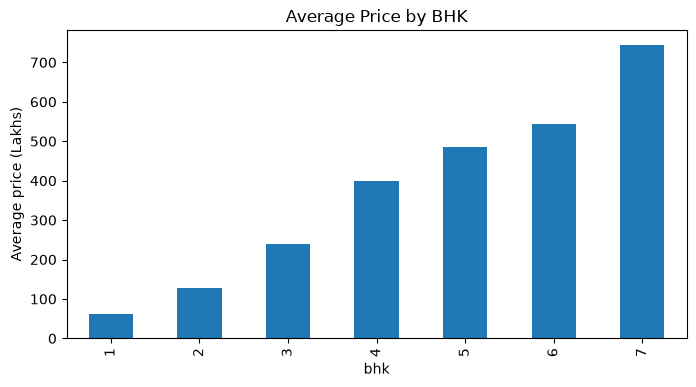

In [61]:
# 27. Average price by BHK
clean.groupby("bhk")["price_lakhs"].mean().plot(kind="bar", figsize=(8, 4))
plt.ylabel("Average price (Lakhs)")
plt.title("Average Price by BHK")
plt.show()

In [62]:
# 28. Average price per sqft by status and age
print(clean.groupby("status")["price_per_sqft"].mean())
print()
print(clean.groupby("age")["price_per_sqft"].mean())

status
Ready to move         12980.795360
Under Construction    14711.152988
Name: price_per_sqft, dtype: float64

age
New        13787.032986
Resale     13230.070757
Unknown    14473.215292
Name: price_per_sqft, dtype: float64


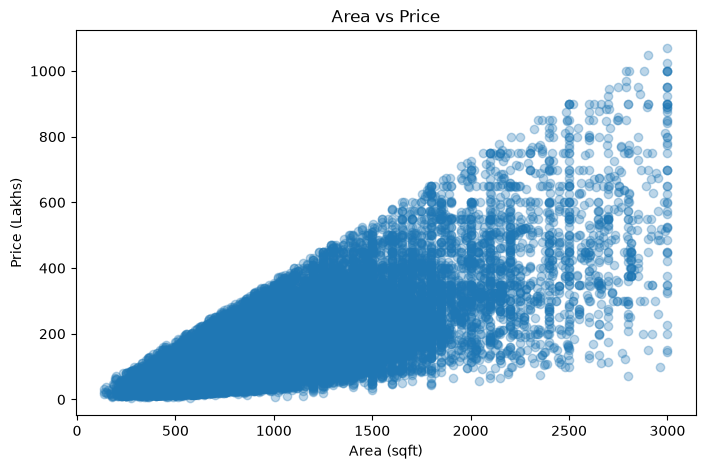

In [63]:
# 29. Area vs price
plt.figure(figsize=(8, 5))
plt.scatter(clean["area"], clean["price_lakhs"], alpha=0.3)
plt.xlabel("Area (sqft)")
plt.ylabel("Price (Lakhs)")
plt.title("Area vs Price")
plt.show()

In [64]:
# 30. Correlation between numeric columns
corr = clean[["bhk", "area", "price_lakhs", "price_per_sqft"]].corr()
print(corr)

                     bhk      area  price_lakhs  price_per_sqft
bhk             1.000000  0.811312     0.703859        0.345761
area            0.811312  1.000000     0.729951        0.166786
price_lakhs     0.703859  0.729951     1.000000        0.729073
price_per_sqft  0.345761  0.166786     0.729073        1.000000


In [65]:
# 31. Final check on cleaned data
print("Shape:", clean.shape)
print()
print(clean.isnull().sum())
print()
clean.head()

Shape: (53215, 9)

bhk               0
type              0
locality          0
area              0
region            0
status            0
age               0
price_lakhs       0
price_per_sqft    0
dtype: int64



,bhk,type,locality,area,region,status,age,price_lakhs,price_per_sqft
0,2,Apartment,Radheya Sai Enclave Building No 2,640,Naigaon East,Under Construction,New,52.51,8204.687500
1,2,Apartment,Romell Serene,610,Borivali West,Under Construction,New,173.00,28360.655738
2,2,Apartment,Soundlines Codename Urban Rainforest,876,Panvel,Under Construction,New,59.98,6847.031963
3,2,Apartment,Origin Oriana,659,Mira Road East,Under Construction,New,94.11,14280.728376
4,5,Villa,Agami Estancia,2921,Boisar,Under Construction,New,199.00,6812.735365


In [66]:
# 32. Save the cleaned data
clean.to_csv("Mumbai_House_Prices_Cleaned.csv", index=False)
print("Saved")

Saved
